In [ ]:
import pandas as pd
df=pd.read_csv('/content/advertising.csv')
df

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,14.0
197,177.0,9.3,6.4,14.8
198,283.6,42.0,66.2,25.5


In [ ]:
df.shape

(200, 4)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [ ]:
df.isnull().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


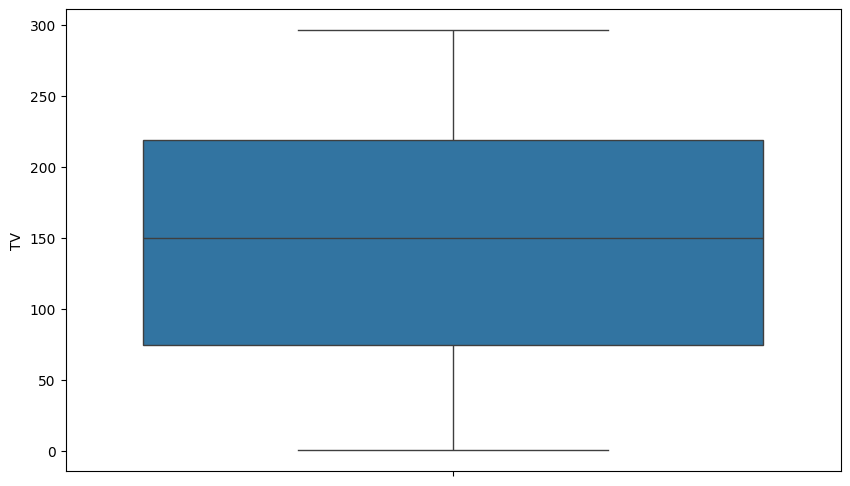

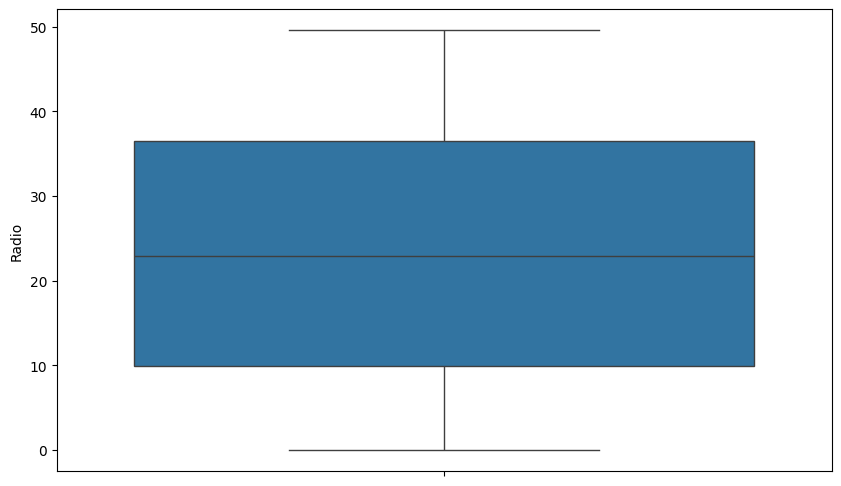

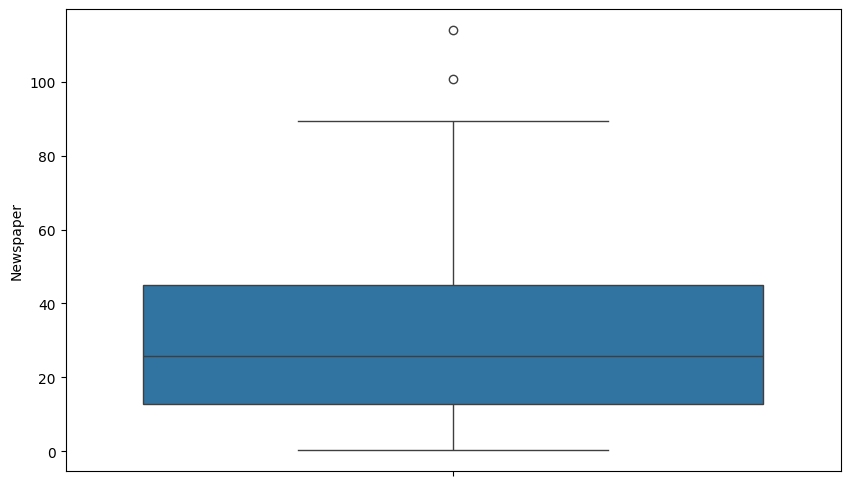

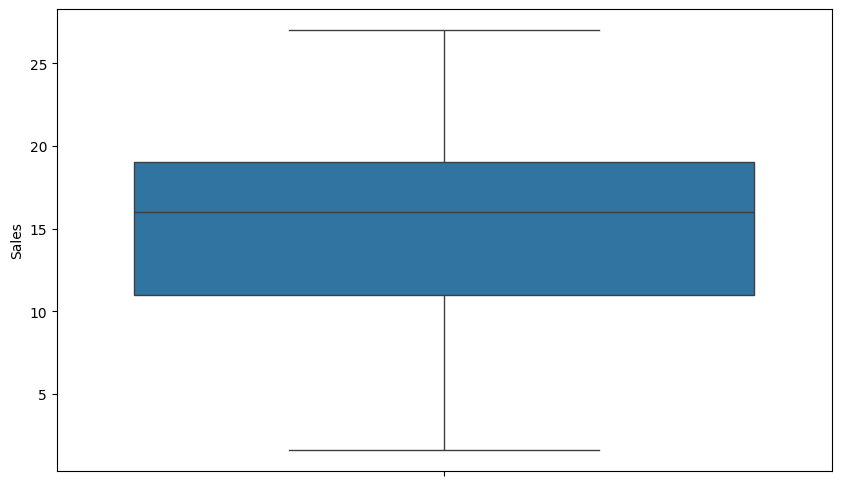

In [ ]:
for col in df.columns:
  plt.figure(figsize=(10,6))
  sns.boxplot(df[col])
  plt.show()

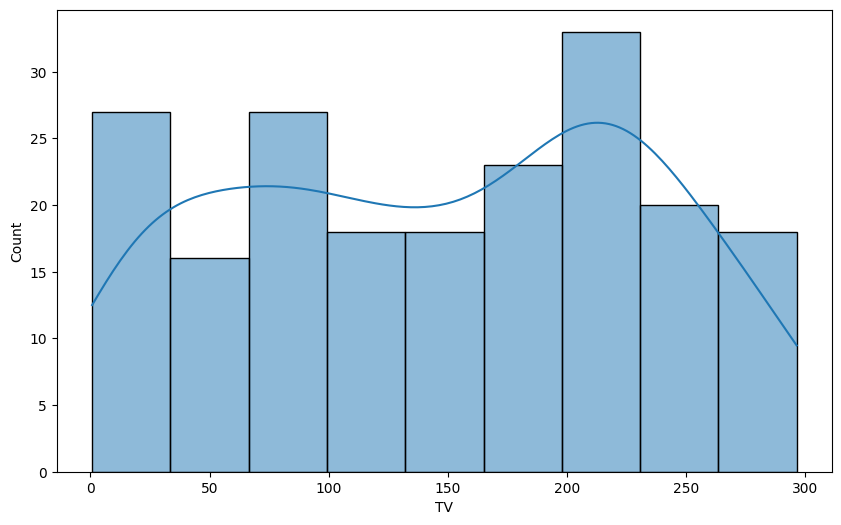

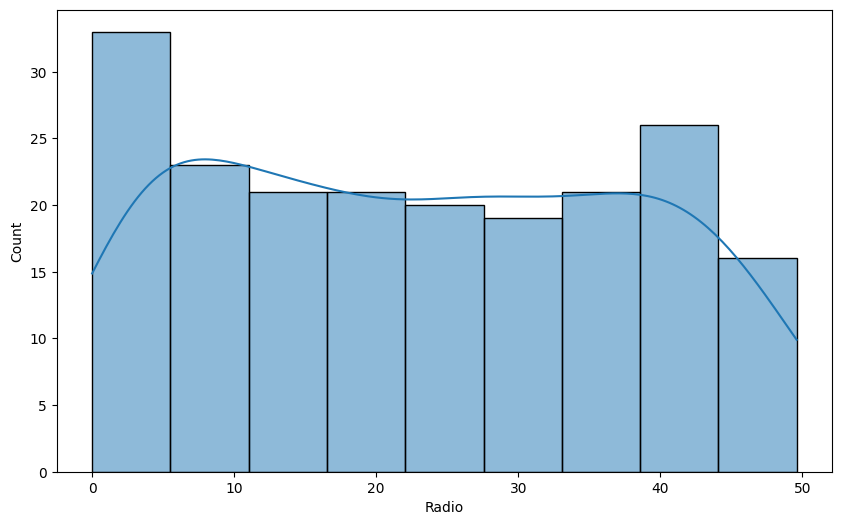

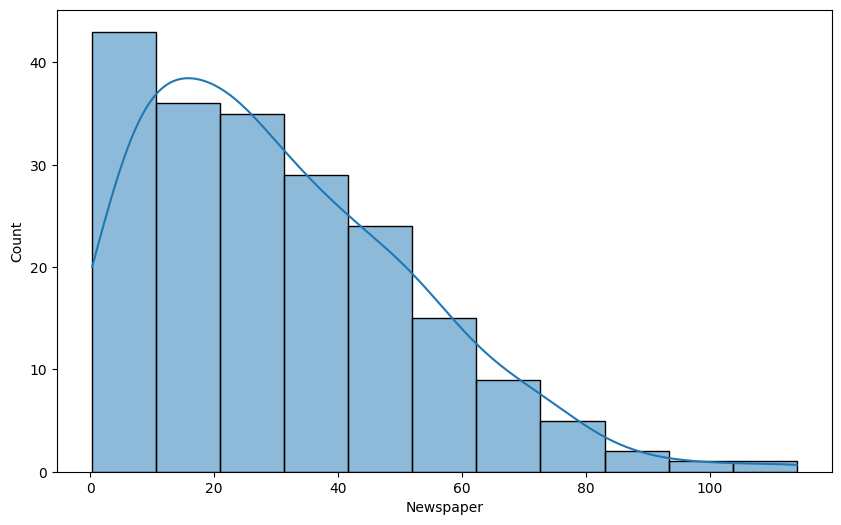

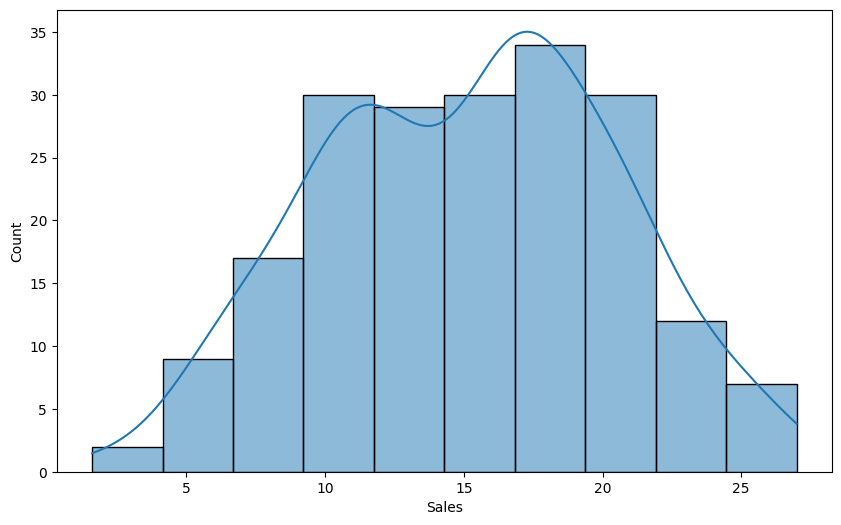

In [ ]:
for col in df.columns:
  plt.figure(figsize=(10,6))
  sns.histplot(df[col],kde=True)
  plt.show()

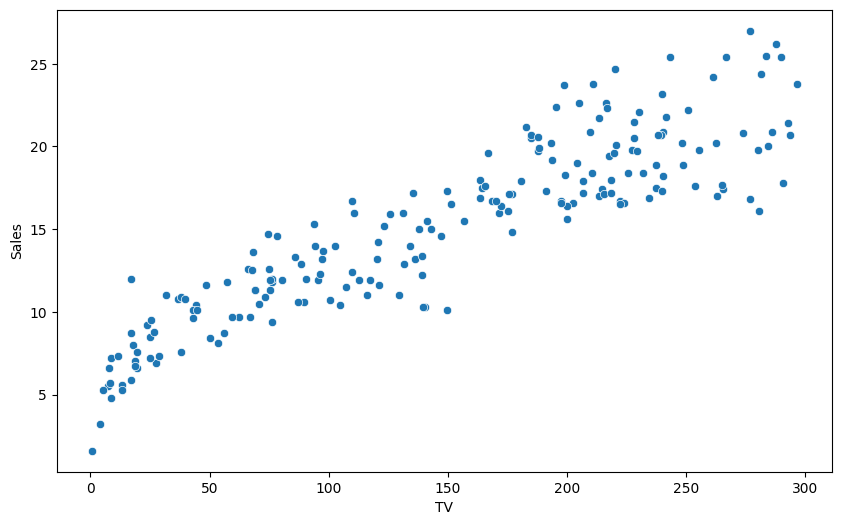

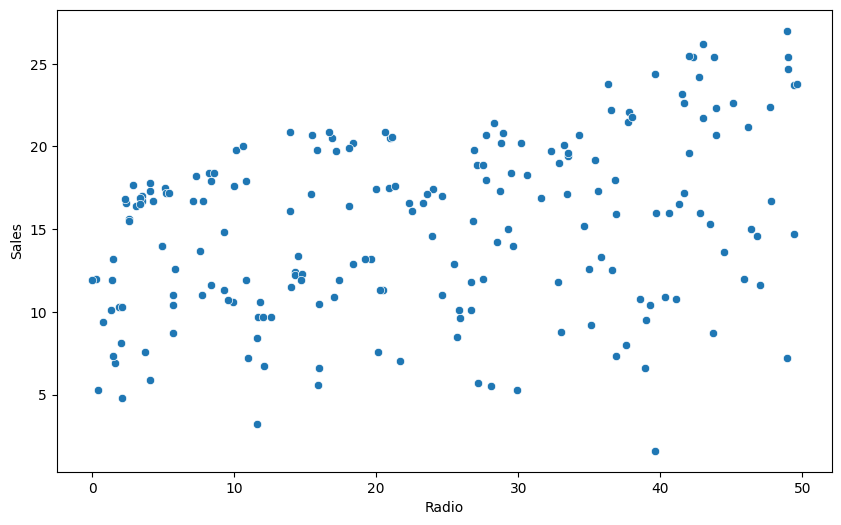

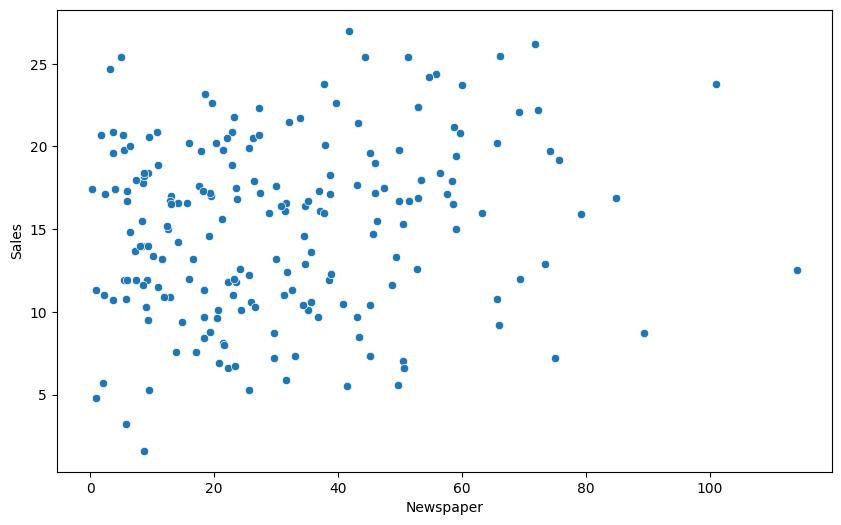

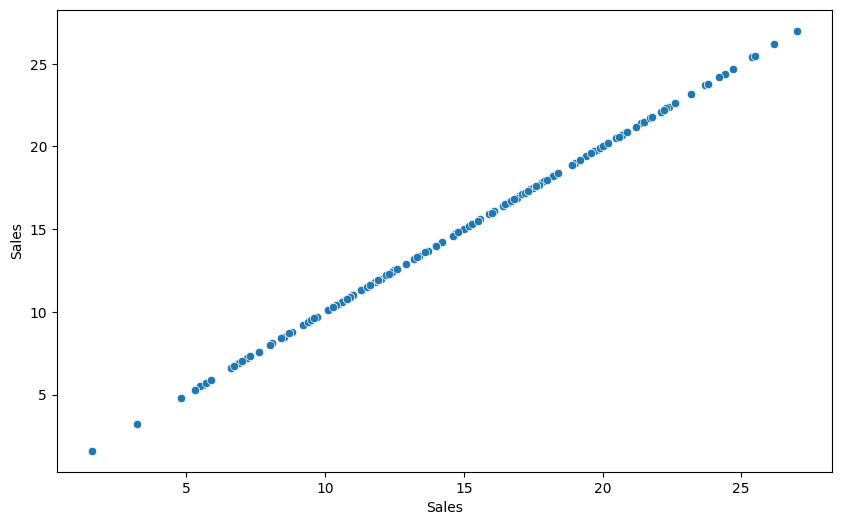

In [ ]:
for col in df.columns:
  plt.figure(figsize=(10,6))
  sns.scatterplot(x=df[col],y=df['Sales'])
  plt.show()

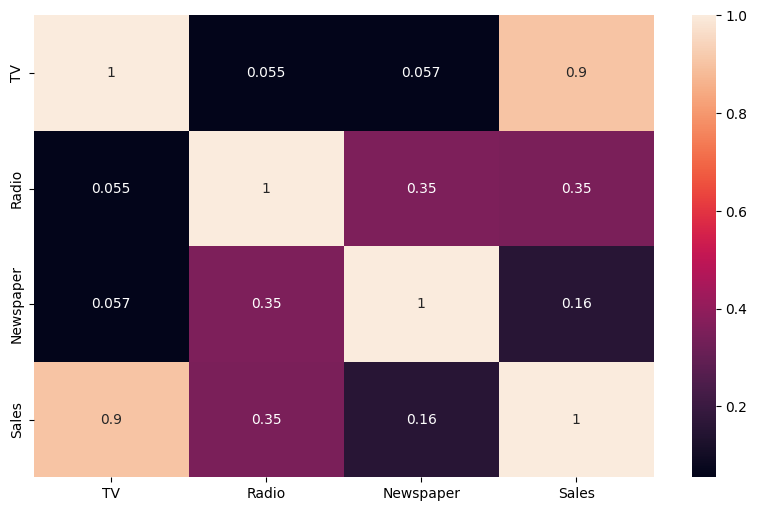

In [ ]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sns.heatmap(corr,annot=True)
plt.show()

In [ ]:
X=df.drop('Sales',axis=1)
y=df['Sales']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
poly=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [ ]:
X_train_poly

array([[1.00000e+00, 1.16000e+02, 7.70000e+00, ..., 5.92900e+01,
        1.77870e+02, 5.33610e+02],
       [1.00000e+00, 1.77000e+02, 9.30000e+00, ..., 8.64900e+01,
        5.95200e+01, 4.09600e+01],
       [1.00000e+00, 4.31000e+01, 2.67000e+01, ..., 7.12890e+02,
        9.37170e+02, 1.23201e+03],
       ...,
       [1.00000e+00, 2.17700e+02, 3.35000e+01, ..., 1.12225e+03,
        1.97650e+03, 3.48100e+03],
       [1.00000e+00, 1.65600e+02, 1.00000e+01, ..., 1.00000e+02,
        1.76000e+02, 3.09760e+02],
       [1.00000e+00, 2.80200e+02, 1.01000e+01, ..., 1.02010e+02,
        2.16140e+02, 4.57960e+02]])

In [ ]:
X_train_poly[0]

array([1.0000e+00, 1.1600e+02, 7.7000e+00, 2.3100e+01, 1.3456e+04,
       8.9320e+02, 2.6796e+03, 5.9290e+01, 1.7787e+02, 5.3361e+02])

In [ ]:
from sklearn.linear_model import LinearRegression
lin_reg=LinearRegression()
model = lin_reg.fit(X_train_poly,y_train)


In [ ]:
y_pred = model.predict(X_test_poly)


In [ ]:
y_pred

array([17.562438  , 21.96285664, 22.07580481,  7.34916293, 23.23684435,
       12.37109504, 22.12872506,  8.76904874, 17.01492635, 16.91480608,
        7.86402513,  9.1023732 , 17.43691412,  5.99987179, 13.70960498,
       15.38247085,  6.28283192, 18.02070399, 10.95120455, 20.20193781,
       20.93683157, 13.01896785,  9.65505427, 22.48602888, 10.0006458 ,
        8.88804873, 21.83258724, 14.37821146, 11.24748724,  6.08610266,
       16.1977029 , 10.4879825 , 22.56616524,  9.20046174, 19.54142042,
       21.31849501, 11.27647626, 21.73705841, 13.18303888,  7.12553149])

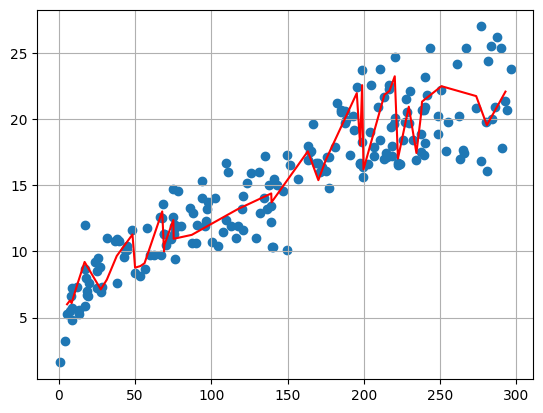

In [ ]:
plt.scatter(df['TV'], df['Sales'], label = 'RealData')
X_test_tv = X_test['TV']

sort_idx_test = np.argsort(X_test_tv)

X_test_tv_sorted = X_test_tv.iloc[sort_idx_test]

y_pred_sorted = y_pred[sort_idx_test]

plt.plot(X_test_tv_sorted, y_pred_sorted, color = 'red', label = 'Poly Reg Line')

plt.grid()
plt.show()

In [ ]:
print(lin_reg.score(X_train_poly, y_train))
print(lin_reg.score(X_test_poly, y_test))

0.9288133512730626


ValueError: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.